# ЛР-3. Дерево решений

Своя реализация CART (`src/tree.py`): критерий Джини для классификации и
дисперсии для регрессии, поиск разбиения векторизован — для каждого признака
сортируем значения в узле и считаем профили сумм.

Дерево не требует масштабирования признаков (важно для дальнейшего сравнения).

In [1]:
# --- общая подготовка: путь к корню репозитория, импорт своих модулей ---
import sys
from pathlib import Path

# корень репозитория ищем вверх по дереву по маркеру src/ — ноутбук можно
# запускать из своей папки или из корня
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.prep import StandardScaler, time_split
from src import metrics

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7.5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# --- данные: панели MOEX и хронологическое разбиение ---
shares = pd.read_csv(ROOT / "data/processed/shares_features.csv", parse_dates=["date"])
bonds = pd.read_csv(ROOT / "data/processed/bonds_features.csv", parse_dates=["date"])

SHARE_FEATS = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # лаги доходности
    "vol_5", "vol_20",                                            # волатильность
    "ma_ratio_5", "ma_ratio_20",                                  # отклонение от средних
    "hl_range", "oc_range",                                       # диапазон дня
    "vol_rel", "val_rel", "trd_rel",                              # относительные объёмы
    "rsi_14", "weekday", "month", "market_ret_1",                 # RSI, календарь, рынок
]
BOND_FEATS = [
    "YIELDCLOSE", "dyield_1", "dyield_5", "dyield_20",            # уровень и изменения доходности
    "ret_1", "ret_5", "ret_20", "vol_20",                         # цена и волатильность
    "DURATION", "COUPONPERCENT", "years_to_mat",                  # параметры выпуска
    "val_rel", "trd_rel", "price_to_face", "is_ofz",              # ликвидность, ОФЗ
]

# обучение — прошлое, тест — будущее; перемешивать нельзя, иначе утечка из будущего
sh_tr, sh_te = time_split(shares, split_date="2025-01-01")
bd_tr, bd_te = time_split(bonds, split_date="2025-10-01")

Xc_tr, yc_tr = sh_tr[SHARE_FEATS].to_numpy("float32"), sh_tr["target_up"].to_numpy()
Xc_te, yc_te = sh_te[SHARE_FEATS].to_numpy("float32"), sh_te["target_up"].to_numpy()
Xr_tr, yr_tr = bd_tr[BOND_FEATS].to_numpy("float32"), bd_tr["target_next_yield"].to_numpy()
Xr_te, yr_te = bd_te[BOND_FEATS].to_numpy("float32"), bd_te["target_next_yield"].to_numpy()

# масштабирование обучаем только на трейне
sc_c, sc_r = StandardScaler().fit(Xc_tr), StandardScaler().fit(Xr_tr)
Xc_tr_s, Xc_te_s = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

print(f"акции:     {len(sh_tr):,} обучение / {len(sh_te):,} тест, признаков {len(SHARE_FEATS)}")
print(f"облигации: {len(bd_tr):,} обучение / {len(bd_te):,} тест, признаков {len(BOND_FEATS)}")
print("доля роста в тесте:", round(yc_te.mean(), 4))

акции:     37,154 обучение / 22,468 тест, признаков 19
облигации: 8,459 обучение / 10,468 тест, признаков 15
доля роста в тесте: 0.4633


In [3]:
# --- сохранение метрик для итогового сравнения (06_comparison.ipynb) ---
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RESULT_FILE = RESULTS / "results.jsonl"


def save_result(lab, task, model, values):
    """Идемпотентно записывает строку метрик в results.jsonl."""
    rows = []
    if RESULT_FILE.exists():
        rows = [json.loads(line) for line in RESULT_FILE.read_text(encoding="utf-8").splitlines() if line]
    row = {"lab": lab, "task": task, "model": model,
           **{k: round(float(v), 4) for k, v in values.items()}}
    rows = [r for r in rows if not (r["lab"] == lab and r["task"] == task and r["model"] == model)]
    rows.append(row)
    RESULT_FILE.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in rows) + "\n",
                           encoding="utf-8")
    return row


def show(res):
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

## 1. Бейзлайн: sklearn

In [4]:
# --- бейзлайн sklearn: дерево с той же глубиной ---
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

base_c = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED).fit(Xc_tr, yc_tr)
r = metrics.classification_report(yc_te, base_c.predict(Xc_te), base_c.predict_proba(Xc_te)[:, 1])
show(r); save_result("lab3_tree", "classification", "sklearn tree", r)

base_r = DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=SEED).fit(Xr_tr, yr_tr)
rr = metrics.regression_report(yr_te, base_r.predict(Xr_te))
show(rr); save_result("lab3_tree", "regression", "sklearn tree", rr)

{'accuracy': 0.5241, 'precision': 0.4835, 'recall': 0.3969, 'f1': 0.436, 'tp': 4132, 'fp': 4414, 'tn': 7644, 'fn': 6278, 'roc_auc': 0.5139}
{'rmse': 1.1334, 'mae': 0.5652, 'r2': 0.9782}


{'lab': 'lab3_tree',
 'task': 'regression',
 'model': 'sklearn tree',
 'rmse': 1.1334,
 'mae': 0.5652,
 'r2': 0.9782}

## 2. Своя реализация

Ожидаем совпадения со sklearn при детерминированных гиперпараметрах
(различия возможны только в обработке связей при равных значениях признака).

In [5]:
# --- своё дерево: те же гиперпараметры ---
from src.tree import DecisionTree

my_c = DecisionTree(task="classification", max_depth=6, min_samples_leaf=50).fit(Xc_tr, yc_tr)
r = metrics.classification_report(yc_te, my_c.predict(Xc_te), my_c.predict_proba(Xc_te))
show(r); save_result("lab3_tree", "classification", "my tree", r)

my_r = DecisionTree(task="regression", max_depth=8, min_samples_leaf=10).fit(Xr_tr, yr_tr)
rr = metrics.regression_report(yr_te, my_r.predict(Xr_te))
show(rr); save_result("lab3_tree", "regression", "my tree", rr)

print("accuracy: своё", round(r["accuracy"], 4), "| sklearn", round(base_c.score(Xc_te, yc_te), 4))

{'accuracy': 0.5241, 'precision': 0.4835, 'recall': 0.3969, 'f1': 0.436, 'tp': 4132, 'fp': 4414, 'tn': 7644, 'fn': 6278, 'roc_auc': 0.5138}
{'rmse': 1.1336, 'mae': 0.5653, 'r2': 0.9782}
accuracy: своё 0.5241 | sklearn 0.5241


## 3. Гипотеза 1: глубина

Глубина управляет сложностью. Перебираем 2…12 и смотрим, где наступает
переобучение (train vs test).

depth= 2  train=0.5563  test=0.5441


depth= 3  train=0.5582  test=0.5455


depth= 4  train=0.5698  test=0.5374


depth= 6  train=0.5856  test=0.5241


depth= 8  train=0.6086  test=0.5223


depth=10  train=0.6280  test=0.5287


depth=12  train=0.6449  test=0.5165


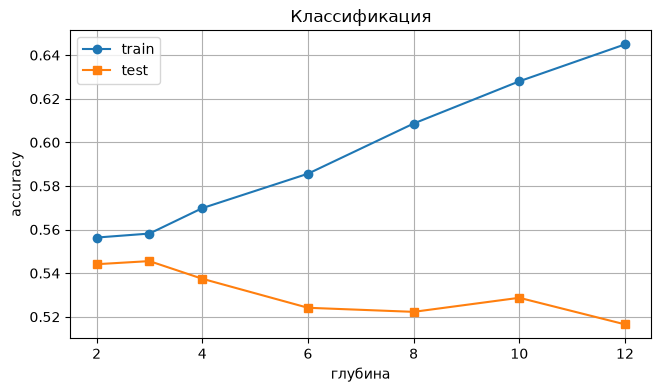

In [6]:
# --- глубина: train и test метрики, поиск точки переобучения ---
rows = []
for d in (2, 3, 4, 6, 8, 10, 12):
    m = DecisionTree(task="classification", max_depth=d, min_samples_leaf=50).fit(Xc_tr, yc_tr)
    tr_acc = metrics.accuracy(yc_tr, m.predict(Xc_tr))
    te_acc = metrics.accuracy(yc_te, m.predict(Xc_te))
    rows.append((d, tr_acc, te_acc))
    print(f"depth={d:2d}  train={tr_acc:.4f}  test={te_acc:.4f}")
plt.plot([r[0] for r in rows], [r[1] for r in rows], "o-", label="train")
plt.plot([r[0] for r in rows], [r[2] for r in rows], "s-", label="test")
plt.xlabel("глубина"); plt.ylabel("accuracy"); plt.legend(); plt.title("Классификация"); plt.show()

## 4. Гипотеза 2: минимальный размер листа

`min_samples_leaf` — второй регулятор. На финансовых данных шум в листьях
особенно вреден: лист из 10 наблюдений фиксирует случайность.

In [7]:
# --- min_samples_leaf при глубине 8 ---
for leaf in (10, 30, 100, 300, 1000):
    m = DecisionTree(task="classification", max_depth=8, min_samples_leaf=leaf).fit(Xc_tr, yc_tr)
    te_acc = metrics.accuracy(yc_te, m.predict(Xc_te))
    auc = metrics.roc_auc(yc_te, m.predict_proba(Xc_te))
    print(f"leaf={leaf:5d}  test accuracy={te_acc:.4f}  AUC={auc:.4f}")

leaf=   10  test accuracy=0.5158  AUC=0.5062


leaf=   30  test accuracy=0.5195  AUC=0.5133


leaf=  100  test accuracy=0.5235  AUC=0.5141


leaf=  300  test accuracy=0.5344  AUC=0.5258


leaf= 1000  test accuracy=0.5389  AUC=0.5325


## 5. Гипотеза 3: какие признаки дерево реально использует

Перестановочная важность: перемешиваем столбец на тесте и смотрим падение метрики.
Не требует доступа к внутренностям дерева и работает для любой модели.
Считаем для базового дерева (глубина 6, лист 50) — оно же используется в сравнении.

weekday        +0.01656
market_ret_1   +0.00766
ret_3          +0.00312
ret_10         +0.00138
hl_range       +0.00027
ret_1          +0.00000
ret_5          +0.00000
ret_20         +0.00000
vol_5          +0.00000
vol_20         +0.00000
oc_range       +0.00000
vol_rel        +0.00000
val_rel        +0.00000
rsi_14         +0.00000
ma_ratio_20    -0.00009
ma_ratio_5     -0.00018
trd_rel        -0.00067
month          -0.00076
ret_2          -0.00450


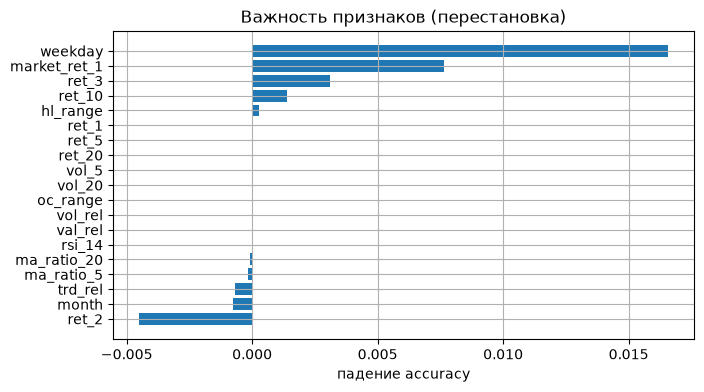

In [8]:
# --- permutation importance на тесте (классификация) ---
rng = np.random.default_rng(SEED)
base_acc = metrics.accuracy(yc_te, my_c.predict(Xc_te))
imp = []
for j, name in enumerate(SHARE_FEATS):
    Xp = Xc_te.copy()
    Xp[:, j] = rng.permutation(Xp[:, j])
    imp.append((name, base_acc - metrics.accuracy(yc_te, my_c.predict(Xp))))
imp.sort(key=lambda t: -t[1])
for name, d in imp:
    print(f"{name:14s} {d:+.5f}")
plt.barh([n for n, _ in imp[::-1]], [d for _, d in imp[::-1]])
plt.xlabel("падение accuracy"); plt.title("Важность признаков (перестановка)"); plt.show()

## 6. Регрессия: глубина и переобучение

На облигациях дерево быстро запоминает уровень доходности конкретного выпуска,
поэтому важно ограничивать глубину.

In [9]:
# --- регрессия: глубина против RMSE ---
for d in (2, 4, 6, 8, 10):
    m = DecisionTree(task="regression", max_depth=d, min_samples_leaf=10).fit(Xr_tr, yr_tr)
    tr = metrics.rmse(yr_tr, m.predict(Xr_tr))
    te = metrics.rmse(yr_te, m.predict(Xr_te))
    print(f"depth={d:2d}  RMSE train={tr:.4f}  test={te:.4f}")

depth= 2  RMSE train=3.0848  test=2.6135
depth= 4  RMSE train=1.7230  test=1.2717


depth= 6  RMSE train=1.4621  test=1.0800


depth= 8  RMSE train=1.3748  test=1.1336


depth=10  RMSE train=1.3418  test=1.1386

## Выводы

1. Своё дерево совпадает со sklearn по accuracy и ROC-AUC при одинаковых
   гиперпараметрах — реализация корректна (тест «эталон vs свой»).
2. Оптимум глубины — 2–3: дальше train accuracy растёт (0.556 → 0.645),
   а тест падает (0.545 → 0.517) — классическое переобучение на шуме.
3. `min_samples_leaf` — более сильный регулятор, чем глубина: при depth = 8
   лист на 1000 наблюдений поднимает accuracy с 0.516 до 0.539 и AUC до 0.533.
4. Перестановочная важность: дерево опирается в основном на день недели
   (падение accuracy 1.7 п.п.) и рыночный фактор (0.8 п.п.), из доходностей —
   на трёхдневную; RSI и объёмные признаки дерево почти не использует.
5. В регрессии оптимум — глубина 6 (RMSE 1.08); глубже тест не улучшается:
   дерево запоминает конкретные выпуски.
6. Дерево нестабильно и не умеет экстраполировать — отсюда переход к лесу и бустингу.